# 07 — Comment les couches s'enchaînent : résidus, LayerNorm et rétropropagation

**Chapitre 2** · durée conseillée : 40 min · CPU uniquement (≈ 1 min de calcul) · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/chapitre_2/07_enchainement_backprop.ipynb)

![Parcours](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_2/figures/00_parcours.png)

Nous avons construit les pièces séparément : embeddings, attention, FeedForward. Un GPT les **empile**. Ce notebook répond à deux questions :

1. **Vers l'avant (*forward*)** : comment la sortie d'une couche devient-elle l'entrée de la suivante, et que se passe-t-il pour les formes des tenseurs ?
2. **Vers l'arrière (*backward*)** : quand on appelle `loss.backward()`, comment le signal d'erreur traverse-t-il toutes les couches, et pourquoi **les poids d'une couche influencent-ils l'apprentissage des autres** ?

Nous verrons que deux ingrédients, les **connexions résiduelles** et la **LayerNorm**, sont ce qui rend un réseau profond entraînable.

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme minigpt.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/chapitre_2

In [1]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

texte, tok, train_data, val_data = minigpt.preparer_donnees("shakespeare")
V = tok.vocab_size

PyTorch 2.14.1+cu130 | périphérique : cpu


## 1. La règle de la chaîne sur un réseau à deux couches

Prenons le plus petit réseau possible, avec des **nombres** (pas de tenseurs) :

$$x \xrightarrow{\ \times w_1\ } a \xrightarrow{\ \text{ReLU}\ } h \xrightarrow{\ \times w_2\ } y \longrightarrow \mathcal{L} = (y - t)^2$$

Avec $x = 2$, $t = 1$, $w_1 = 0{,}5$, $w_2 = -1{,}5$ : $a = 1$, $h = 1$, $y = -1{,}5$, $\mathcal{L} = 6{,}25$.

**Backward, en partant de la fin** (règle de la chaîne : on multiplie les dérivées locales) :

| Quantité | Calcul | Valeur |
|---|---|---|
| $\partial\mathcal{L}/\partial y$ | $2(y - t)$ | $-5$ |
| $\partial\mathcal{L}/\partial w_2$ | $\partial\mathcal{L}/\partial y \times h$ | $-5 \times 1 = -5$ |
| $\partial\mathcal{L}/\partial h$ | $\partial\mathcal{L}/\partial y \times w_2$ | $-5 \times (-1{,}5) = 7{,}5$ |
| $\partial\mathcal{L}/\partial a$ | $\partial\mathcal{L}/\partial h \times \text{ReLU}'(a)$ | $7{,}5 \times 1 = 7{,}5$ |
| $\partial\mathcal{L}/\partial w_1$ | $\partial\mathcal{L}/\partial a \times x$ | $7{,}5 \times 2 = 15$ |

**Lisez la dernière ligne :** $\dfrac{\partial\mathcal{L}}{\partial w_1} = 2(y-t)\cdot w_2 \cdot \text{ReLU}'(a)\cdot x$.

- Le gradient de la **première** couche contient $w_2$, le poids de la **seconde** couche. **Ce que la couche 1 apprend dépend des poids de la couche 2.**
- Le gradient de la **seconde** couche contient $h$, la sortie de la **première**. **Ce que la couche 2 apprend dépend de ce que produit la couche 1.**

Vérifions avec autograd, puis regardons deux cas extrêmes.

In [2]:
def petit_reseau(w1_val, w2_val, x=2.0, t=1.0):
    w1 = torch.tensor(w1_val, requires_grad=True)
    w2 = torch.tensor(w2_val, requires_grad=True)
    a = w1 * x
    h = torch.relu(a)
    y = w2 * h
    loss = (y - t) ** 2
    loss.backward()
    return loss.item(), w1.grad.item(), w2.grad.item()

for titre, w1v, w2v in [("cas du tableau", 0.5, -1.5),
                        ("w2 = 0 : la couche 2 « coupe » le signal", 0.5, 0.0),
                        ("w1 < 0 : ReLU éteinte (neurone mort)", -0.5, -1.5)]:
    L, g1, g2 = petit_reseau(w1v, w2v)
    print(f"{titre:42s} loss={L:5.2f}  dL/dw1={g1:6.2f}  dL/dw2={g2:6.2f}")

cas du tableau                             loss= 6.25  dL/dw1= 15.00  dL/dw2= -5.00
w2 = 0 : la couche 2 « coupe » le signal   loss= 1.00  dL/dw1= -0.00  dL/dw2= -2.00
w1 < 0 : ReLU éteinte (neurone mort)       loss= 1.00  dL/dw1=  0.00  dL/dw2= -0.00


- **`w2 = 0`** : la couche 1 ne reçoit **aucun** gradient, alors qu'elle n'est pas en cause. Une couche haute peut **bloquer** l'apprentissage des couches basses.
- **ReLU éteinte** : plus aucun gradient pour **personne** en amont, et la couche 2 ne peut rien apprendre non plus (son entrée $h$ vaut 0).

Dans un réseau de `L` couches, le gradient d'une couche basse est un **produit de `L` facteurs**. Si ces facteurs sont souvent < 1, le produit **s'évanouit** (*vanishing gradient*) ; s'ils sont souvent > 1, il **explose**. C'est le problème central des réseaux profonds (Glorot & Bengio, 2010).

---
## 2. Le bloc Transformer : LayerNorm + résidus

### LayerNorm : normaliser chaque position

`nn.LayerNorm(C)` prend **chaque vecteur de position séparément** et le recentre (moyenne 0) et le réduit (écart-type 1) **sur ses `C` canaux**, puis applique une échelle et un décalage appris (`γ`, `β`) :

$$\text{LN}(x) = \gamma \odot \frac{x - \mu(x)}{\sigma(x) + \varepsilon} + \beta$$

But : garder des activations d'échelle raisonnable d'une couche à l'autre, quelle que soit la profondeur (Ba et al., 2016). Elle ne mélange **ni les positions, ni les exemples**.

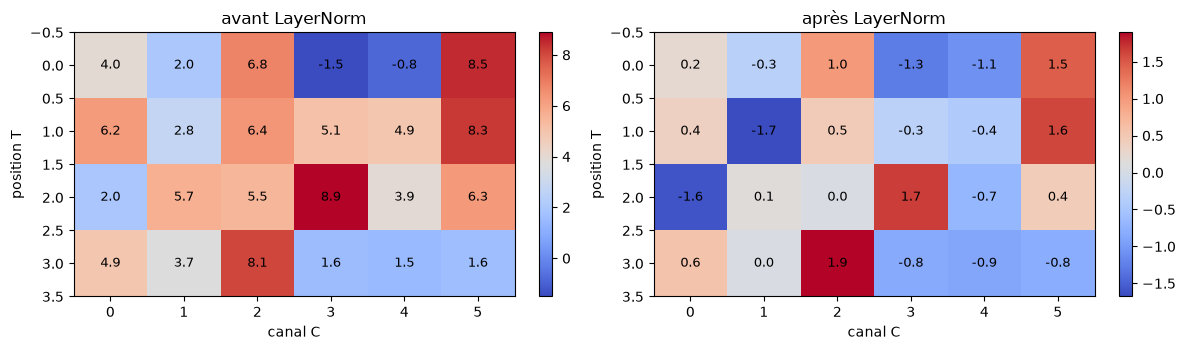

moyenne de chaque position après : [0.0, 0.0, -0.0, 0.0]
écart-type de chaque position après : [1.0, 1.0, 1.0, 1.0]


In [3]:
gen = torch.Generator().manual_seed(2027)
x_norm = torch.randn(1, 4, 6, generator=gen) * 3 + 5
y_norm = nn.LayerNorm(6, elementwise_affine=False)(x_norm)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, M, titre in [(axes[0], x_norm[0], "avant LayerNorm"), (axes[1], y_norm[0], "après LayerNorm")]:
    im = ax.imshow(M, cmap="coolwarm", aspect="auto"); ax.set_title(titre)
    ax.set_xlabel("canal C"); ax.set_ylabel("position T")
    for i in range(4):
        for j in range(6):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=.05)
plt.tight_layout(); plt.show()
print("moyenne de chaque position après :", [round(v, 3) for v in y_norm[0].mean(-1).tolist()])
print("écart-type de chaque position après :", [round(v, 3) for v in y_norm[0].std(-1, unbiased=False).tolist()])

### Les connexions résiduelles : additionner au lieu de remplacer

Au lieu de `x = f(x)`, on écrit **`x = x + f(x)`** : chaque sous-couche **ajoute** sa contribution à `x` au lieu de le remplacer (He et al., 2016). Condition : `f(x)` doit avoir **la même forme** que `x`. C'est pour cela que la multi-head attention se termine par une projection vers `C` et que le FeedForward revient à `C`.

Le bloc complet (version **pré-norm**, comme GPT-2) :

In [4]:
class Block(nn.Module):
    """Bloc Transformer (pré-norm) : communication (attention) puis calcul (FeedForward)."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.sa = minigpt.MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = minigpt.FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # connexion résiduelle n°1
        x = x + self.ffwd(self.ln2(x))   # connexion résiduelle n°2
        return x


bloc = Block(n_embd=64, n_head=4, block_size=32, dropout=0.0)
x = torch.randn(2, 10, 64)
print("entrée :", tuple(x.shape), "-> sortie :", tuple(bloc(x).shape), "(même forme : on peut empiler)")

entrée : (2, 10, 64) -> sortie : (2, 10, 64) (même forme : on peut empiler)


## 3. Suivre un batch à travers tout le réseau (*forward*)

Prenons un GPT de 2 blocs (le code complet sera détaillé au notebook 08) et accrochons un **hook** à chaque couche : une petite fonction appelée automatiquement après chaque `forward`, qui affiche la forme de la sortie. On voit ainsi **l'ordre exact** dans lequel les couches s'enchaînent.

In [5]:
torch.manual_seed(0)
petit = minigpt.GPTLanguageModel(V, block_size=8, n_embd=16, n_head=2, n_layer=2, dropout=0.0)
xb, yb = minigpt.get_batch(train_data, batch_size=4, block_size=8)

trace = []
def hook(nom):
    def f(module, entree, sortie):
        trace.append((nom, tuple(sortie.shape)))
    return f

a_suivre = ["token_embedding_table", "position_embedding_table"]
for i in range(2):
    a_suivre += [f"blocks.{i}.ln1", f"blocks.{i}.sa.heads.0", f"blocks.{i}.sa.heads.1", f"blocks.{i}.sa",
                 f"blocks.{i}.ln2", f"blocks.{i}.ffwd.net.0", f"blocks.{i}.ffwd.net.1", f"blocks.{i}.ffwd", f"blocks.{i}"]
a_suivre += ["ln_f", "lm_head"]
modules = dict(petit.named_modules())
poignees = [modules[n].register_forward_hook(hook(n)) for n in a_suivre]
logits, loss = petit(xb, yb)
for p in poignees: p.remove()

print(f"entrée idx : {tuple(xb.shape)}")
for nom, forme in trace:
    print(f"  {nom:28s} -> {forme}")
print(f"loss (scalaire) : {loss.item():.3f}")

entrée idx : (4, 8)
  token_embedding_table        -> (4, 8, 16)
  position_embedding_table     -> (8, 16)
  blocks.0.ln1                 -> (4, 8, 16)
  blocks.0.sa.heads.0          -> (4, 8, 8)
  blocks.0.sa.heads.1          -> (4, 8, 8)
  blocks.0.sa                  -> (4, 8, 16)
  blocks.0.ln2                 -> (4, 8, 16)
  blocks.0.ffwd.net.0          -> (4, 8, 64)
  blocks.0.ffwd.net.1          -> (4, 8, 64)
  blocks.0.ffwd                -> (4, 8, 16)
  blocks.0                     -> (4, 8, 16)
  blocks.1.ln1                 -> (4, 8, 16)
  blocks.1.sa.heads.0          -> (4, 8, 8)
  blocks.1.sa.heads.1          -> (4, 8, 8)
  blocks.1.sa                  -> (4, 8, 16)
  blocks.1.ln2                 -> (4, 8, 16)
  blocks.1.ffwd.net.0          -> (4, 8, 64)
  blocks.1.ffwd.net.1          -> (4, 8, 64)
  blocks.1.ffwd                -> (4, 8, 16)
  blocks.1                     -> (4, 8, 16)
  ln_f                         -> (4, 8, 16)
  lm_head                      -> (4, 8, 6

**À lire dans la trace :**
- Les deux embeddings produisent `(4, 8, 16)` et `(8, 16)` ; leur somme est le **point d'entrée du flux résiduel**.
- Chaque tête produit `(4, 8, 8)` (= `C / n_head` canaux) ; la multi-head les recolle à `(4, 8, 16)`.
- Le FeedForward passe par `(4, 8, 64)` (= `4C`) puis revient à `(4, 8, 16)`.
- **Tout le cœur du réseau garde la forme `(B, T, C)`** : c'est le « flux résiduel ». Seule `lm_head` le convertit en `(B, T, V)`.

---
## 4. Le flux résiduel, vu de l'arrière (*backward*)

![Flux résiduel](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_2/figures/07_flux_residuel.png)

Une bonne image (Elhage et al., 2021) : `x` est un **flux** (*residual stream*) qui traverse le réseau de bas en haut. Chaque attention et chaque FeedForward **lit** le flux (via LayerNorm) et **écrit** dans le flux (par addition). Après `L` blocs :

$$x_L = x_0 + f_1(\cdot) + f_2(\cdot) + \dots + f_{2L}(\cdot)$$

**Pourquoi c'est crucial pour le gradient :** la dérivée de $x + f(x)$ par rapport à $x$ vaut $1 + f'(x)$. Le « $1$ » signifie que le gradient de la loss arrive **directement**, sans être multiplié, jusqu'aux premières couches et jusqu'aux embeddings. Sans résidus, il doit traverser **toutes** les couches et devient un produit de `2L` facteurs (comme au §1).

### Expérience : 8 blocs, avec et sans résidus / LayerNorm

On construit quatre variantes d'un GPT de **8 blocs**, identiques sauf pour ces deux ingrédients. Pour chacune, on mesure **la norme du gradient** reçu par chaque bloc après **un seul** `backward()`, puis on entraîne 200 pas.

In [6]:
class BlocVariable(nn.Module):
    def __init__(self, C, n_head, T, residus, layernorm):
        super().__init__()
        self.residus = residus
        self.sa = minigpt.MultiHeadAttention(C, n_head, T, dropout=0.0)
        self.ffwd = minigpt.FeedForward(C, dropout=0.0)
        self.ln1 = nn.LayerNorm(C) if layernorm else nn.Identity()
        self.ln2 = nn.LayerNorm(C) if layernorm else nn.Identity()

    def forward(self, x):
        if self.residus:
            x = x + self.sa(self.ln1(x))
            return x + self.ffwd(self.ln2(x))
        x = self.sa(self.ln1(x))          # sans résidu : on REMPLACE x
        return self.ffwd(self.ln2(x))


class GPTVariable(nn.Module):
    def __init__(self, residus, layernorm, C=64, n_head=4, n_layer=8, T=64):
        super().__init__()
        self.tok = nn.Embedding(V, C); self.pos = nn.Embedding(T, C)
        self.blocks = nn.Sequential(*[BlocVariable(C, n_head, T, residus, layernorm) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(C); self.lm_head = nn.Linear(C, V)

    def forward(self, idx, targets):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        logits = self.lm_head(self.ln_f(self.blocks(x)))
        return F.cross_entropy(logits.view(-1, V), targets.view(-1))


variantes = {"résidus + LayerNorm": (True, True), "résidus seuls": (True, False),
             "LayerNorm seule": (False, True), "ni l'un ni l'autre": (False, False)}
normes, courbes = {}, {}
for nom, (r, ln) in variantes.items():
    torch.manual_seed(0)
    m = GPTVariable(r, ln)
    xb, yb = minigpt.get_batch(train_data, 16, 64)
    m(xb, yb).backward()
    normes[nom] = [math.sqrt(sum((p.grad ** 2).sum().item() for p in b.parameters())) for b in m.blocks]
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    h = []
    for _ in range(200):
        xb, yb = minigpt.get_batch(train_data, 16, 64)
        loss = m(xb, yb); opt.zero_grad(); loss.backward(); opt.step(); h.append(loss.item())
    courbes[nom] = h
    print(f"{nom:22s} gradient bloc 0 : {normes[nom][0]:.1e} | bloc 7 : {normes[nom][-1]:.1e} | loss après 200 pas : {sum(h[-20:]) / 20:.3f}")

résidus + LayerNorm    gradient bloc 0 : 4.0e-01 | bloc 7 : 4.4e-01 | loss après 200 pas : 2.477


résidus seuls          gradient bloc 0 : 5.6e-01 | bloc 7 : 7.6e-01 | loss après 200 pas : 2.475


LayerNorm seule        gradient bloc 0 : 1.2e+00 | bloc 7 : 6.0e+00 | loss après 200 pas : 3.319


ni l'un ni l'autre     gradient bloc 0 : 1.9e-07 | bloc 7 : 5.0e+00 | loss après 200 pas : 3.319


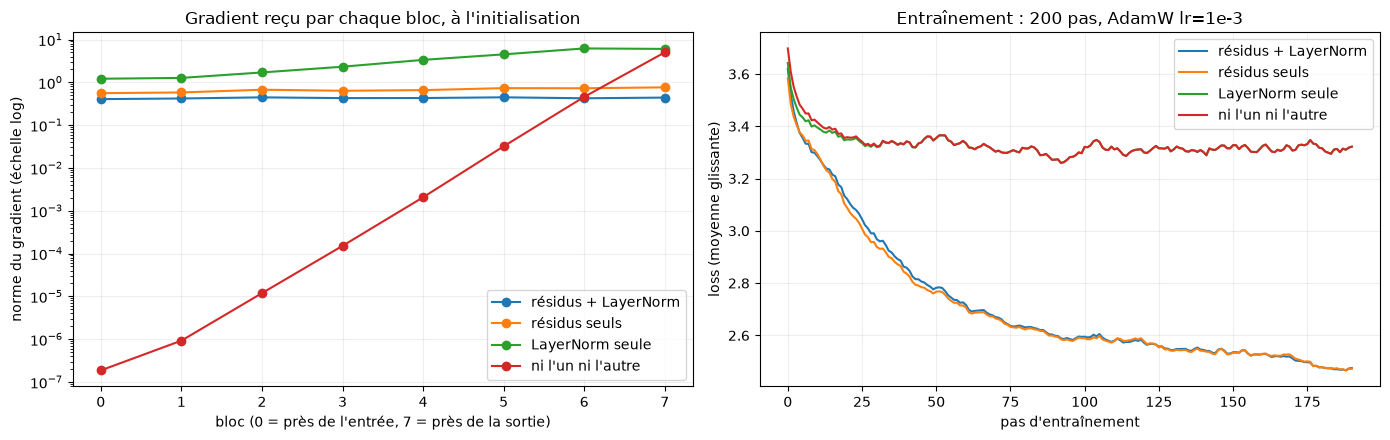

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nom, n in normes.items():
    axes[0].plot(range(8), n, marker="o", label=nom)
axes[0].set_yscale("log"); axes[0].set_xlabel("bloc (0 = près de l'entrée, 7 = près de la sortie)")
axes[0].set_ylabel("norme du gradient (échelle log)"); axes[0].set_title("Gradient reçu par chaque bloc, à l'initialisation")
axes[0].legend(); axes[0].grid(alpha=.2)
for nom, h in courbes.items():
    lisse = torch.tensor(h).unfold(0, 10, 1).mean(1)
    axes[1].plot(lisse, label=nom)
axes[1].set_xlabel("pas d'entraînement"); axes[1].set_ylabel("loss (moyenne glissante)")
axes[1].set_title("Entraînement : 200 pas, AdamW lr=1e-3"); axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

**Lecture :**
- **Sans résidus ni LayerNorm**, le gradient du bloc 0 est **plus de dix millions de fois plus petit** que celui du bloc 7 : les premiers blocs n'apprennent pratiquement rien. Le réseau se comporte comme s'il n'avait que ses dernières couches.
- **Avec résidus**, tous les blocs reçoivent un gradient du **même ordre de grandeur** : l'autoroute du « $+1$ » fonctionne.
- La LayerNorm seule évite l'effondrement, mais le gradient reste déséquilibré (5 fois plus fort en haut qu'en bas) et la loss reste aussi haute que sans rien : **ce sont les résidus qui font la différence**. Sur ce petit réseau, « résidus seuls » fait aussi bien que « résidus + LayerNorm » ; la LayerNorm devient indispensable pour des réseaux plus profonds et des entraînements plus longs, quand l'échelle du flux résiduel grandit à chaque addition.

*(AdamW normalise la taille des pas, ce qui masque en partie le problème : avec SGD, l'écart serait encore plus spectaculaire.)*

---
## 5. Une couche influence l'apprentissage des autres

### Vers l'avant : changer un bloc change tout ce qui est au-dessus

Perturbons légèrement les poids du **bloc 0** seulement, et mesurons de combien le flux résiduel change après chaque bloc.

In [8]:
torch.manual_seed(0)
gpt = minigpt.GPTLanguageModel(V, block_size=64, n_embd=64, n_head=4, n_layer=4, dropout=0.0)
xb, yb = minigpt.get_batch(train_data, 16, 64)

def flux(modele):
    sorties = []
    poignees = [b.register_forward_hook(lambda m, e, s: sorties.append(s.detach())) for b in modele.blocks]
    logits, _ = modele(xb)
    for p in poignees: p.remove()
    return sorties, logits.detach()

avant, logits_avant = flux(gpt)
import copy
gpt_modifie = copy.deepcopy(gpt)
with torch.no_grad():
    for p in gpt_modifie.blocks[0].parameters():
        p.add_(0.05 * torch.randn_like(p))          # petite perturbation du bloc 0 uniquement
apres, logits_apres = flux(gpt_modifie)

for i, (a, b) in enumerate(zip(avant, apres)):
    print(f"après le bloc {i} : variation relative du flux = {((a - b).norm() / a.norm()).item():.3f}")
print(f"logits         : variation relative           = {((logits_avant - logits_apres).norm() / logits_avant.norm()).item():.3f}")

après le bloc 0 : variation relative du flux = 0.315
après le bloc 1 : variation relative du flux = 0.314
après le bloc 2 : variation relative du flux = 0.315
après le bloc 3 : variation relative du flux = 0.314
logits         : variation relative           = 0.296


Modifier le bloc 0 modifie **l'entrée de tous les blocs suivants** : ce que chaque bloc doit apprendre dépend de ce que les blocs du dessous lui envoient.

### Vers l'arrière : le gradient d'un bloc dépend des poids des blocs du dessus

C'est la généralisation du §1 (où $\partial\mathcal{L}/\partial w_1$ contenait $w_2$). Calculons le gradient du **bloc 0**, puis modifions **seulement le bloc 3** et recalculons le gradient du bloc 0.

In [9]:
def gradient_bloc0(modele):
    modele.zero_grad()
    _, loss = modele(xb, yb)
    loss.backward()
    return torch.cat([p.grad.flatten() for p in modele.blocks[0].parameters()])

g_avant = gradient_bloc0(gpt)
gpt_bloc3 = copy.deepcopy(gpt)
with torch.no_grad():
    for p in gpt_bloc3.blocks[3].parameters():
        p.add_(0.05 * torch.randn_like(p))          # on ne touche QU'AU bloc 3
g_apres = gradient_bloc0(gpt_bloc3)

print(f"variation relative du gradient du bloc 0 : {((g_avant - g_apres).norm() / g_avant.norm()).item():.3f}")
print("cosinus entre les deux gradients :", round(F.cosine_similarity(g_avant, g_apres, dim=0).item(), 3))

variation relative du gradient du bloc 0 : 0.368
cosinus entre les deux gradients : 0.935


Les poids du bloc 0 n'ont pas changé, et pourtant **leur gradient a changé** : la direction dans laquelle le bloc 0 va évoluer dépend des poids du bloc 3, parce que le signal d'erreur passe par lui pendant `backward()`.

**C'est pourquoi on entraîne toutes les couches ensemble**, avec une seule loss : à chaque pas, chaque couche s'ajuste en tenant compte de l'état actuel de toutes les autres. Les couches **co-évoluent** :

1. **forward** : bloc 0 → bloc 1 → … → logits → loss (chaque couche dépend de celles du dessous) ;
2. **backward** : loss → lm_head → bloc 3 → … → bloc 0 → embeddings (chaque gradient dépend des couches du dessus) ;
3. **step** : AdamW met à jour **tous** les poids en même temps ;
4. au pas suivant, chaque couche voit des voisines légèrement différentes, et ainsi de suite.

### Combien chaque partie bouge-t-elle lors d'un pas ?

In [10]:
gpt_pas = copy.deepcopy(gpt)
opt = torch.optim.AdamW(gpt_pas.parameters(), lr=1e-3)
avant = {n: p.detach().clone() for n, p in gpt_pas.named_parameters()}
_, loss = gpt_pas(xb, yb)
opt.zero_grad(); loss.backward(); opt.step()

groupes = {}
for n, p in gpt_pas.named_parameters():
    g = n.split(".")[0] if not n.startswith("blocks") else ".".join(n.split(".")[:2])
    d, w = groupes.get(g, (0.0, 0.0))
    groupes[g] = (d + ((p.detach() - avant[n]) ** 2).sum().item(), w + (avant[n] ** 2).sum().item())
for g, (d, w) in groupes.items():
    print(f"{g:26s} |Δw| / |w| = {math.sqrt(d / w):.1e}")

token_embedding_table      |Δw| / |w| = 9.2e-04
position_embedding_table   |Δw| / |w| = 9.9e-04
blocks.0                   |Δw| / |w| = 1.2e-02
blocks.1                   |Δw| / |w| = 1.2e-02
blocks.2                   |Δw| / |w| = 1.2e-02
blocks.3                   |Δw| / |w| = 1.2e-02
ln_f                       |Δw| / |w| = 1.4e-03
lm_head                    |Δw| / |w| = 1.4e-02


**Aucune partie n'est laissée de côté.** Avec AdamW, chaque poids bouge d'environ `lr = 1e-3` en valeur absolue (notebook 02). En **relatif**, cela fait ≈ 1 % pour les couches linéaires des blocs et de `lm_head` (leurs poids initiaux sont petits, ≈ 0,1) et ≈ 0,1 % pour les embeddings et la LayerNorm finale (poids initiaux ≈ 1).

## À retenir

- **Forward :** chaque couche reçoit la sortie de la précédente ; au cœur du GPT, la forme reste `(B, T, C)` : c'est le **flux résiduel**.
- **Backward :** règle de la chaîne. Le gradient d'une couche est un **produit** des dérivées des couches au-dessus : il dépend de **leurs poids**. Et les entrées de chaque couche dépendent des couches du dessous. **Les couches apprennent ensemble.**
- **Résidus** (`x = x + f(x)`) : le « $+1$ » de la dérivée est une autoroute pour le gradient → toutes les couches apprennent, même dans un réseau profond.
- **LayerNorm** : normalise chaque position sur ses `C` canaux ; garde des activations d'échelle stable. **Pré-norm** : `x + f(LN(x))`.
- Sans ces deux ingrédients, un réseau de 8 blocs voit son gradient s'évanouir (×1e-7 au bloc 0).

**Questions de vérification**
1. Dans `x = x + self.sa(self.ln1(x))`, pourquoi `self.sa` doit-il renvoyer exactement la forme de `x` ?
2. Si les poids de `lm_head` étaient tous nuls, que recevraient comme gradient les blocs ? (Pensez au cas `w2 = 0` du §1.)
3. Pourquoi dit-on que la LayerNorm « ne fait pas communiquer les positions » ?

**Suite → 08 :** on assemble tout dans `GPTLanguageModel`.

### Références
- K. He et al., [*Deep Residual Learning for Image Recognition*](https://arxiv.org/abs/1512.03385), CVPR 2016 — les connexions résiduelles.
- J. L. Ba, J. R. Kiros, G. Hinton, [*Layer Normalization*](https://arxiv.org/abs/1607.06450), 2016.
- R. Xiong et al., [*On Layer Normalization in the Transformer Architecture*](https://arxiv.org/abs/2002.04745), ICML 2020 — pourquoi le pré-norm stabilise l'entraînement.
- X. Glorot & Y. Bengio, [*Understanding the difficulty of training deep feedforward neural networks*](https://proceedings.mlr.press/v9/glorot10a.html), AISTATS 2010 — gradients qui s'évanouissent.
- N. Elhage et al., [*A Mathematical Framework for Transformer Circuits*](https://transformer-circuits.pub/2021/framework/index.html), 2021 — l'image du *residual stream*.
- A. Karpathy, [*The spelled-out intro to neural networks and backpropagation: building micrograd*](https://www.youtube.com/watch?v=VMj-3S1tku0) — la rétropropagation construite à la main.
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), §6.5 (*Back-Propagation*).